
# EN3160 – Assignment 3: Neural Networks

**Name:** Deshan W.U.  
**Index Number:** 230130E  

**GitHub Repository:** [EN3160 Assignment 3 – Neural Networks](https://github.com/deshanudara144-ui/EN3160-Assignment-3)



In [1]:
import torch
import torch .nn as nn
import torch .optim as optim
import torchvision
import torchvision .transforms as transforms
import matplotlib . pyplot as plt

Question 1

In [4]:
# 1. Data loading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')



100%|██████████| 170M/170M [1:49:19<00:00, 26.0kB/s]  


Extracting ./data\cifar-10-python.tar.gz to ./data
Files already downloaded and verified


Epoch 1/10, Loss: 1.8097347614765167
Epoch 2/10, Loss: 1.679225182056427
Epoch 3/10, Loss: 1.6212337262630463
Epoch 4/10, Loss: 1.5752793266773224
Epoch 5/10, Loss: 1.5363085768222808
Epoch 6/10, Loss: 1.5035136926174164
Epoch 7/10, Loss: 1.471570742726326
Epoch 8/10, Loss: 1.4460643712282182
Epoch 9/10, Loss: 1.4205351933836936
Epoch 10/10, Loss: 1.3999517545104028


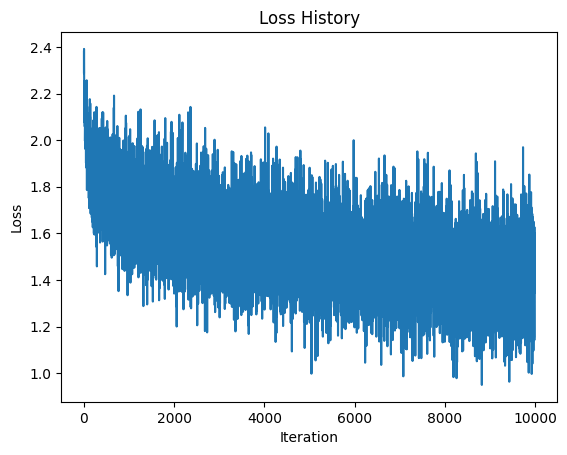

Training accuracy: 53.20%
Test accuracy: 47.72%


In [5]:
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100            # Number of nodes in the middle layer
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-2         # larger init std, needed for the hidden layer
 
# Initialize weights and biases
w1 = torch.randn(Din, H) * std       
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std * 10    
b2 = torch.zeros(K)
 
# Hyperparameters
iterations = 10    #  10 epochs
lr = 1e-1          # learning rate suited to cross-entropy
lr_decay = 0.9     # Learning rate decay
reg = 0            # Regularization
 
loss_history = []
 
# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one-hot
 
        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)   # middle layer, sigmoid
        y_pred = h.mm(w2) + b2                   # Output layer
        # softmax for cross-entropy (max subtracted for stability)
        e = torch.exp(y_pred - y_pred.max(dim=1, keepdim=True).values)
        p = e / e.sum(dim=1, keepdim=True)
 
        # Loss calculation (Cross-entropy with regularization)
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(p + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()
 
        # Backpropagation
        dy_pred = (1.0 / Ntr) * (p - y_train_onehot)    # softmax + cross-entropy gradient
        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)
        dh = dy_pred.mm(w2.t())                         # back through middle layer
        dz1 = dh * h * (1 - h)                          # sigmoid derivative
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)
 
        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2
 
    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")
 
    # Learning rate decay
    lr *= lr_decay
 
# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()
 
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()
 
        # Forward pass 
        h = torch.sigmoid(x_train.mm(w1) + b1)
        y_train_pred = h.mm(w2) + b2
 
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()
 
train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")
 
# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()
 
        # Forward pass 
        h = torch.sigmoid(x_test.mm(w1) + b1)
        y_test_pred = h.mm(w2) + b2
 
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()
 
test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")
 

Question 2

In [8]:
# Q2(a)
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])   # MNIST mean / std
#Data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])   # MNIST mean / std
 
batch_size = 64
trainset = torchvision.datasets.MNIST('./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST('./data', train=False, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

# Model: LeNet-5
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(1, 6, kernel_size=5, padding=2),   
            nn.Tanh(),
            nn.AvgPool2d(2, 2),                          
            nn.Conv2d(6, 16, kernel_size=5),             
            nn.Tanh(),
            nn.AvgPool2d(2, 2))                          
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(),
            nn.Linear(84, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * y.size(0)
            pred = out.argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)
            all_preds.append(pred.cpu())
            all_targets.append(y.cpu())
    return (total_loss / total, 100.0 * correct / total,
            torch.cat(all_preds), torch.cat(all_targets))


#Training 
epochs = 10
lr = 1e-3

model = LeNet5().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

for epoch in range(epochs):
    model.train()
    for x, y in trainloader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()

    tr_loss, tr_acc, _, _ = evaluate(model, trainloader, criterion)
    te_loss, te_acc, _, _ = evaluate(model, testloader, criterion)
    history['train_loss'].append(tr_loss)
    history['test_loss'].append(te_loss)
    history['train_acc'].append(tr_acc)
    history['test_acc'].append(te_acc)
    print(f"Epoch {epoch + 1}/{epochs} | Train loss {tr_loss:.4f}, acc {tr_acc:.2f}% "
          f"| Test loss {te_loss:.4f}, acc {te_acc:.2f}%")

# Results 
_, final_train_acc, _, _ = evaluate(model, trainloader, criterion)
_, final_test_acc, test_preds, test_targets = evaluate(model, testloader, criterion)
print(f"\nLeNet-5 final training accuracy: {final_train_acc:.2f}%")
print(f"LeNet-5 final test accuracy:     {final_test_acc:.2f}%")
print("Parameters:", sum(p.numel() for p in model.parameters()))

# Save for plots and confusion matrix
torch.save({'history': history, 'preds': test_preds, 'targets': test_targets},
           'lenet5_results.pt')

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9.91M/9.91M [00:13<00:00, 714kB/s] 


Extracting ./data\MNIST\raw\train-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28.9k/28.9k [00:00<00:00, 97.0kB/s]


Extracting ./data\MNIST\raw\train-labels-idx1-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1.65M/1.65M [00:02<00:00, 619kB/s] 


Extracting ./data\MNIST\raw\t10k-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]


Extracting ./data\MNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\MNIST\raw

Epoch 1/10 | Train loss 0.0866, acc 97.47% | Test loss 0.0880, acc 97.38%
Epoch 2/10 | Train loss 0.0505, acc 98.47% | Test loss 0.0584, acc 98.25%
Epoch 3/10 | Train loss 0.0399, acc 98.80% | Test loss 0.0585, acc 98.28%
Epoch 4/10 | Train loss 0.0313, acc 99.00% | Test loss 0.0484, acc 98.47%
Epoch 5/10 | Train loss 0.0236, acc 99.28% | Test loss 0.0438, acc 98.62%
Epoch 6/10 | Train loss 0.0191, acc 99.38% | Test loss 0.0393, acc 98.63%
Epoch 7/10 | Train loss 0.0194, acc 99.39% | Test loss 0.0457, acc 98.59%
Epoch 8/10 | Train loss 0.0170, acc 99.45% | Test loss 0.0434, acc 98.75%
Epoch 9/10 | Train loss 0.0105, acc 99.70% | Test loss 0.0412, acc 98.62%
Epoch 10/10 | Train loss 0.0130, acc 99.57% | Test loss 0.0441, acc 98.72%

LeNet-5 final training accuracy: 99.57%
LeNet-5 final test accuracy:     98.72%
Parameters: 61706


In [9]:
# Q2(b): Modern small CNN (3 conv layers + BatchNorm + Dropout) on MNIST
# Model 
class SmallCNN(nn.Module):
    def __init__(self, p_drop=0.3):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, kernel_size=3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(
            block(1, 32),    
            block(32, 64),    
            block(64, 128))   
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p_drop),
            nn.Linear(128 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

def evaluate(model, loader, criterion):
    model.eval()   # disables dropout, uses BatchNorm running statistics
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * y.size(0)
            pred = out.argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)
            all_preds.append(pred.cpu())
            all_targets.append(y.cpu())
    return (total_loss / total, 100.0 * correct / total,
            torch.cat(all_preds), torch.cat(all_targets))

# Training 
epochs = 10
lr = 1e-3

model = SmallCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

for epoch in range(epochs):
    model.train()
    for x, y in trainloader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()

    tr_loss, tr_acc, _, _ = evaluate(model, trainloader, criterion)
    te_loss, te_acc, _, _ = evaluate(model, testloader, criterion)
    history['train_loss'].append(tr_loss)
    history['test_loss'].append(te_loss)
    history['train_acc'].append(tr_acc)
    history['test_acc'].append(te_acc)
    print(f"Epoch {epoch + 1}/{epochs} | Train loss {tr_loss:.4f}, acc {tr_acc:.2f}% "
          f"| Test loss {te_loss:.4f}, acc {te_acc:.2f}%")

# Final results 
_, final_train_acc, _, _ = evaluate(model, trainloader, criterion)
_, final_test_acc, test_preds, test_targets = evaluate(model, testloader, criterion)
print(f"\nSmall CNN final training accuracy: {final_train_acc:.2f}%")
print(f"Small CNN final test accuracy:     {final_test_acc:.2f}%")
print("Parameters:", sum(p.numel() for p in model.parameters()))

# Save for plots and confusion matrix
torch.save({'history': history, 'preds': test_preds, 'targets': test_targets},
           'smallcnn_results.pt')

Epoch 1/10 | Train loss 0.0472, acc 98.47% | Test loss 0.0498, acc 98.53%
Epoch 2/10 | Train loss 0.0785, acc 97.53% | Test loss 0.0789, acc 97.39%
Epoch 3/10 | Train loss 0.0206, acc 99.34% | Test loss 0.0278, acc 99.11%
Epoch 4/10 | Train loss 0.0245, acc 99.24% | Test loss 0.0321, acc 99.04%
Epoch 5/10 | Train loss 0.0144, acc 99.56% | Test loss 0.0247, acc 99.26%
Epoch 6/10 | Train loss 0.0100, acc 99.66% | Test loss 0.0222, acc 99.31%
Epoch 7/10 | Train loss 0.0089, acc 99.70% | Test loss 0.0224, acc 99.39%
Epoch 8/10 | Train loss 0.0085, acc 99.75% | Test loss 0.0238, acc 99.20%
Epoch 9/10 | Train loss 0.0067, acc 99.78% | Test loss 0.0276, acc 99.18%
Epoch 10/10 | Train loss 0.0055, acc 99.83% | Test loss 0.0179, acc 99.40%

Small CNN final training accuracy: 99.83%
Small CNN final test accuracy:     99.40%
Parameters: 241994


C:\Users\ASUS\AppData\Local\Temp\ipykernel_11084\515064981.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  'LeNet-5': torch.load('lenet5_results.pt'),
C:\Users\ASUS\AppD

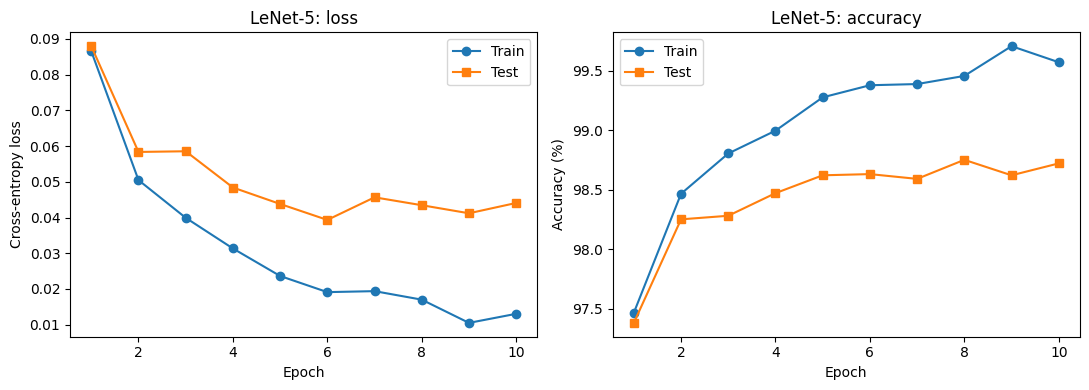

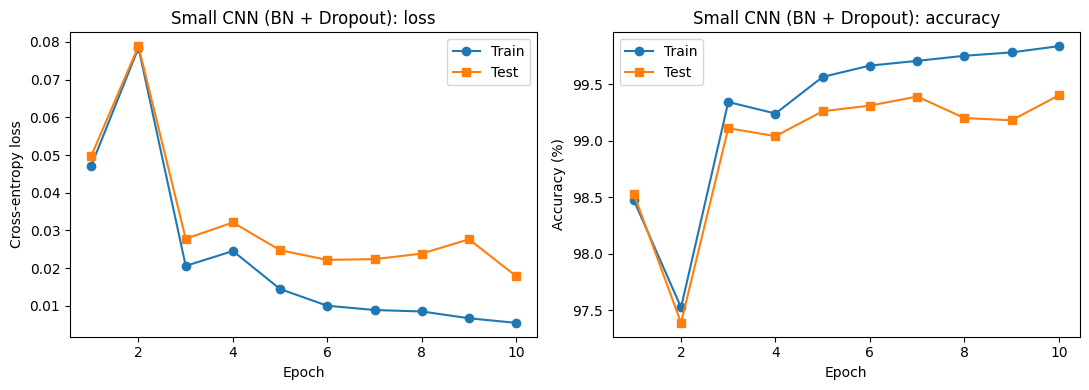

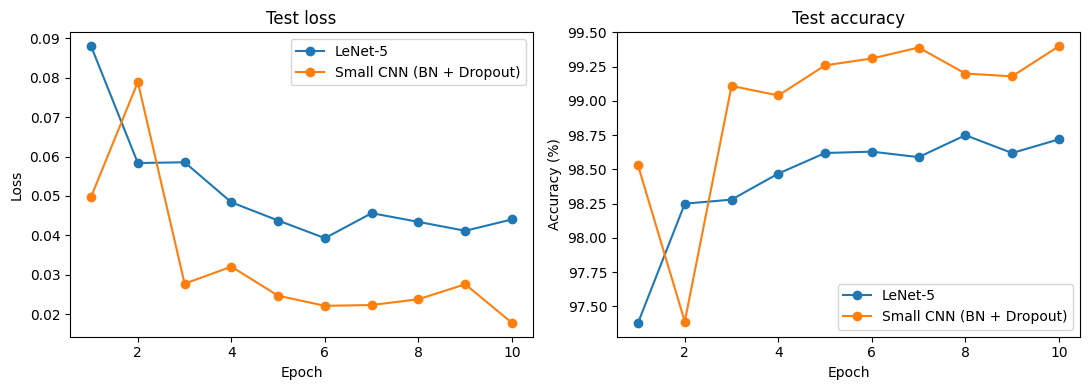

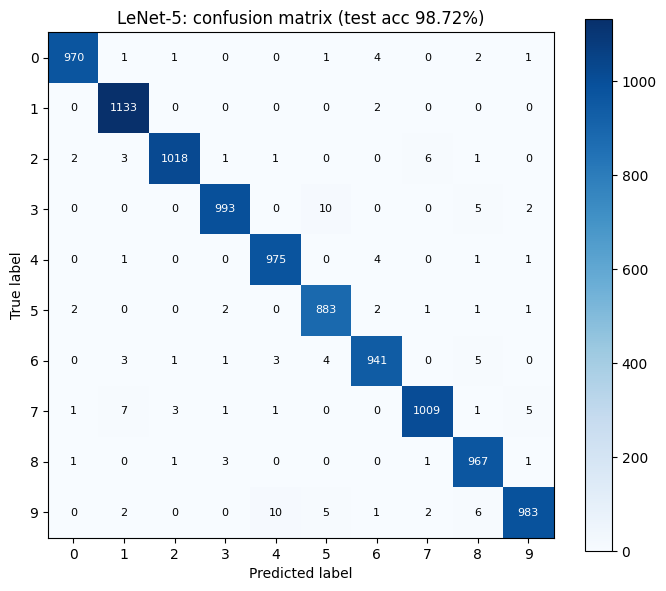

LeNet-5: most common mistakes
  true 9 -> predicted 4: 10 times
  true 3 -> predicted 5: 10 times
  true 7 -> predicted 1: 7 times


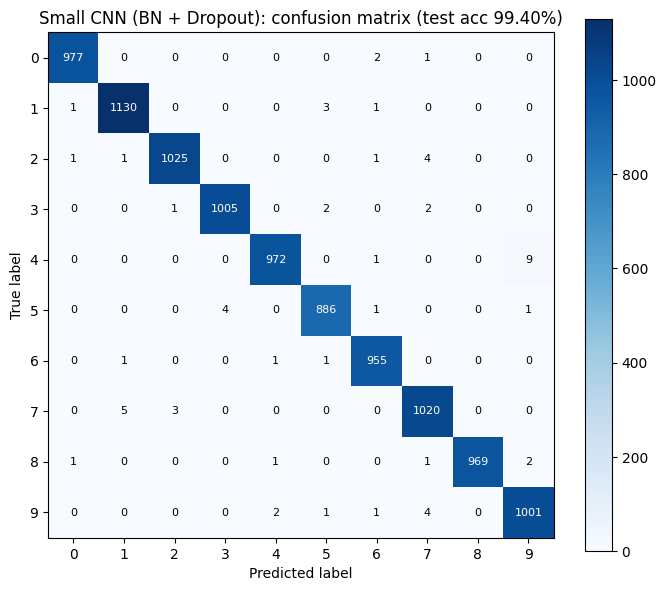

Small CNN (BN + Dropout): most common mistakes
  true 4 -> predicted 9: 9 times
  true 7 -> predicted 1: 5 times
  true 2 -> predicted 7: 4 times


In [10]:
# Q2(c): Per-epoch accuracy/loss plots and test-set confusion matrices
import torch
import matplotlib.pyplot as plt

results = {
    'LeNet-5': torch.load('lenet5_results.pt'),
    'Small CNN (BN + Dropout)': torch.load('smallcnn_results.pt'),
}
class_names = [str(i) for i in range(10)]

# Per-epoch curves 
for name, res in results.items():
    h = res['history']
    epochs = range(1, len(h['train_loss']) + 1)

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(epochs, h['train_loss'], marker='o', label='Train')
    ax[0].plot(epochs, h['test_loss'], marker='s', label='Test')
    ax[0].set_title(f'{name}: loss')
    ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Cross-entropy loss'); ax[0].legend()

    ax[1].plot(epochs, h['train_acc'], marker='o', label='Train')
    ax[1].plot(epochs, h['test_acc'], marker='s', label='Test')
    ax[1].set_title(f'{name}: accuracy')
    ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)'); ax[1].legend()

    plt.tight_layout()
    plt.show()

#  Side-by-side comparison 
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, res in results.items():
    h = res['history']
    epochs = range(1, len(h['test_loss']) + 1)
    ax[0].plot(epochs, h['test_loss'], marker='o', label=name)
    ax[1].plot(epochs, h['test_acc'], marker='o', label=name)
ax[0].set_title('Test loss'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].legend()
ax[1].set_title('Test accuracy'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)'); ax[1].legend()
plt.tight_layout()
plt.show()

# Confusion matrices 
def confusion_matrix(preds, targets, num_classes=10):
    cm = torch.zeros(num_classes, num_classes, dtype=torch.int64)
    for t, p in zip(targets, preds):
        cm[t, p] += 1
    return cm

for name, res in results.items():
    cm = confusion_matrix(res['preds'], res['targets'])
    acc = 100.0 * cm.diag().sum().item() / cm.sum().item()

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm.numpy(), cmap='Blues')
    ax.set_xticks(range(10)); ax.set_xticklabels(class_names)
    ax.set_yticks(range(10)); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted label'); ax.set_ylabel('True label')
    ax.set_title(f'{name}: confusion matrix (test acc {acc:.2f}%)')
    thresh = cm.max().item() / 2
    for i in range(10):
        for j in range(10):
            ax.text(j, i, int(cm[i, j]), ha='center', va='center', fontsize=8,
                    color='white' if cm[i, j] > thresh else 'black')
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

    # Most confused pairs
    off = cm.clone()
    off.fill_diagonal_(0)
    top = torch.topk(off.flatten(), 3)
    print(f'{name}: most common mistakes')
    for val, idx in zip(top.values, top.indices):
        print(f'  true {idx.item() // 10} -> predicted {idx.item() % 10}: {val.item()} times')

Question 3

Classes: ['ants', 'bees'] | Sizes: {'train': 244, 'val': 153}


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [01:24<00:00, 557kB/s] 


Trainable parameters: 11177538
Epoch 1/25 | Train loss 0.5815 acc 0.6803 | Val loss 0.2394 acc 0.9150
Epoch 2/25 | Train loss 0.5249 acc 0.7418 | Val loss 0.2829 acc 0.8889
Epoch 3/25 | Train loss 0.7070 acc 0.7254 | Val loss 0.2537 acc 0.9085
Epoch 4/25 | Train loss 0.4293 acc 0.8115 | Val loss 0.3013 acc 0.8693
Epoch 5/25 | Train loss 0.4423 acc 0.8115 | Val loss 0.2215 acc 0.9216
Epoch 6/25 | Train loss 0.3231 acc 0.8484 | Val loss 0.2751 acc 0.9150
Epoch 7/25 | Train loss 0.4132 acc 0.8156 | Val loss 0.3337 acc 0.8562
Epoch 8/25 | Train loss 0.3731 acc 0.8566 | Val loss 0.2020 acc 0.8954
Epoch 9/25 | Train loss 0.3795 acc 0.8156 | Val loss 0.2242 acc 0.9150
Epoch 10/25 | Train loss 0.3030 acc 0.8648 | Val loss 0.2033 acc 0.9085
Epoch 11/25 | Train loss 0.3731 acc 0.8279 | Val loss 0.2173 acc 0.9150
Epoch 12/25 | Train loss 0.2882 acc 0.8648 | Val loss 0.1796 acc 0.9216
Epoch 13/25 | Train loss 0.3397 acc 0.8484 | Val loss 0.1926 acc 0.9346
Epoch 14/25 | Train loss 0.2586 acc 0.8852

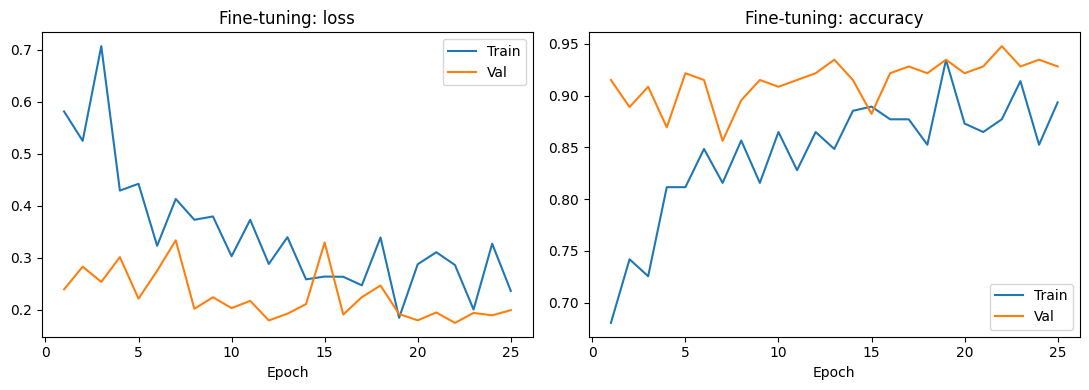

In [2]:
# Q3(a): Fine-tuning a pre-trained ResNet18 (ImageNet1K) on the hymenoptera dataset
# Based on the PyTorch transfer learning tutorial.
import os
import time
import copy
import zipfile
import urllib.request

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0)

# Data loading 
url = 'https://download.pytorch.org/tutorial/hymenoptera_data.zip'
data_dir = os.path.join('data', 'hymenoptera_data')
if not os.path.exists(data_dir):
    os.makedirs('data', exist_ok=True)
    zip_path = os.path.join('data', 'hymenoptera_data.zip')
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall('data')

data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]),
}

image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x])
                  for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                              shuffle=(x == 'train'), num_workers=0)
               for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes
print('Classes:', class_names, '| Sizes:', dataset_sizes)

#Training function 
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()
    best_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(num_epochs):
        for phase in ['train', 'val']:
            model.train() if phase == 'train' else model.eval()
            running_loss, running_corrects = 0.0, 0

            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = (running_corrects.double() / dataset_sizes[phase]).item()
            history[f'{phase}_loss'].append(epoch_loss)
            history[f'{phase}_acc'].append(epoch_acc)

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_wts = copy.deepcopy(model.state_dict())

        print(f"Epoch {epoch + 1}/{num_epochs} | "
              f"Train loss {history['train_loss'][-1]:.4f} acc {history['train_acc'][-1]:.4f} | "
              f"Val loss {history['val_loss'][-1]:.4f} acc {history['val_acc'][-1]:.4f}")

    elapsed = time.time() - since
    print(f'\nTraining complete in {elapsed // 60:.0f}m {elapsed % 60:.0f}s')
    print(f'Best val accuracy: {best_acc:.4f}')
    model.load_state_dict(best_wts)
    return model, history, elapsed

#  Fine-tuning
model_ft = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
num_ftrs = model_ft.fc.in_features
model_ft.fc = nn.Linear(num_ftrs, 2)          # new head: ants / bees
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)   # every parameter updated
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

trainable = sum(p.numel() for p in model_ft.parameters() if p.requires_grad)
print('Trainable parameters:', trainable)

model_ft, history_ft, time_ft = train_model(model_ft, criterion, optimizer_ft,
                                            exp_lr_scheduler, num_epochs=25)

# Plots 
epochs = range(1, len(history_ft['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(epochs, history_ft['train_loss'], label='Train')
ax[0].plot(epochs, history_ft['val_loss'], label='Val')
ax[0].set_title('Fine-tuning: loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(epochs, history_ft['train_acc'], label='Train')
ax[1].plot(epochs, history_ft['val_acc'], label='Val')
ax[1].set_title('Fine-tuning: accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout()
plt.show()

# Save for comparison 
torch.save({'history': history_ft, 'time': time_ft, 'trainable': trainable}, 'finetune_results.pt')

Trainable parameters: 1026
Epoch 1/25 | Train loss 0.8007 acc 0.6025 | Val loss 0.2349 acc 0.9346
Epoch 2/25 | Train loss 0.4869 acc 0.7787 | Val loss 0.2518 acc 0.8758
Epoch 3/25 | Train loss 0.3760 acc 0.8320 | Val loss 0.1849 acc 0.9346
Epoch 4/25 | Train loss 0.4321 acc 0.8033 | Val loss 0.2554 acc 0.9216
Epoch 5/25 | Train loss 0.3520 acc 0.8402 | Val loss 0.2306 acc 0.9281
Epoch 6/25 | Train loss 0.5661 acc 0.7910 | Val loss 0.1736 acc 0.9477
Epoch 7/25 | Train loss 0.5132 acc 0.7787 | Val loss 0.2486 acc 0.9216
Epoch 8/25 | Train loss 0.3860 acc 0.8402 | Val loss 0.1645 acc 0.9542
Epoch 9/25 | Train loss 0.3472 acc 0.8607 | Val loss 0.1774 acc 0.9477
Epoch 10/25 | Train loss 0.3142 acc 0.8770 | Val loss 0.1687 acc 0.9477
Epoch 11/25 | Train loss 0.4025 acc 0.8484 | Val loss 0.1700 acc 0.9542
Epoch 12/25 | Train loss 0.3956 acc 0.8238 | Val loss 0.1793 acc 0.9542
Epoch 13/25 | Train loss 0.4077 acc 0.8197 | Val loss 0.1914 acc 0.9477
Epoch 14/25 | Train loss 0.3684 acc 0.8730 | V

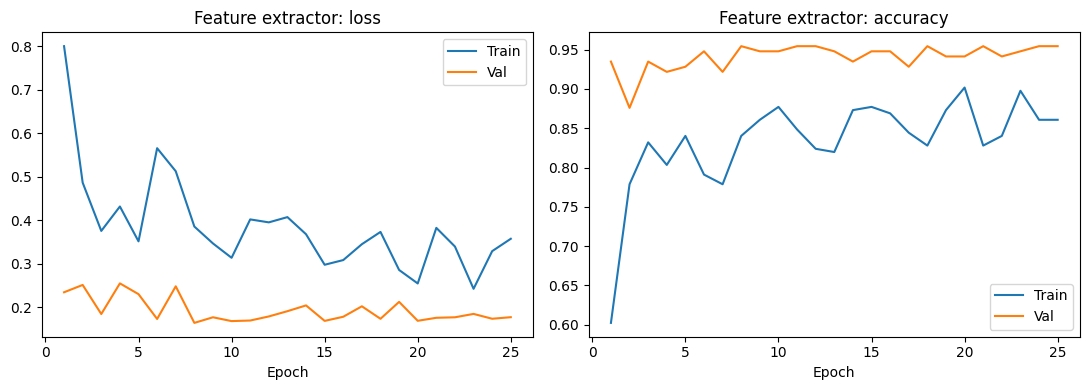

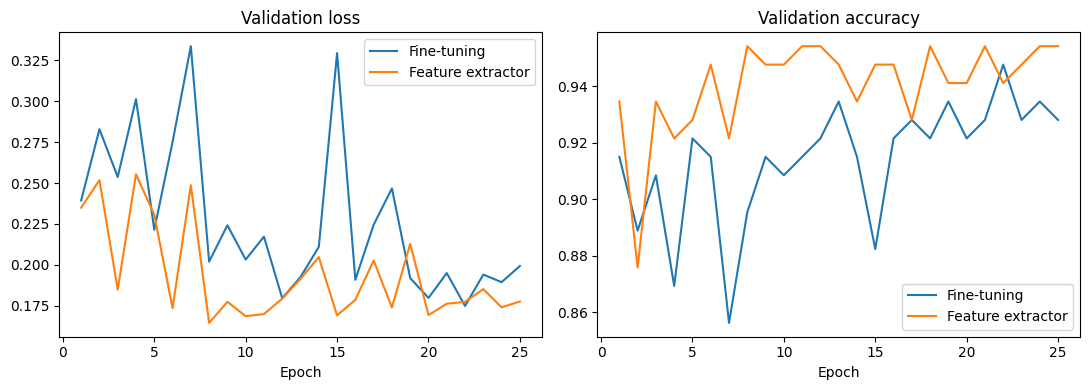

Method                Best val acc    Time (s)    Trainable params
Fine-tuning                 0.9477         415          11,177,538
Feature extractor           0.9542         187               1,026


In [5]:
# Q3(b): Pre-trained ResNet18 (ImageNet1K) used as a FIXED feature extractor
#  Feature extractor: freeze the backbone 
model_conv = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for param in model_conv.parameters():
    param.requires_grad = False               # freeze all pre-trained layers

num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)       
model_conv = model_conv.to(device)


optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler_conv = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

trainable_conv = sum(p.numel() for p in model_conv.parameters() if p.requires_grad)
print('Trainable parameters:', trainable_conv)

model_conv, history_conv, time_conv = train_model(model_conv, criterion, optimizer_conv,
                                                  exp_lr_scheduler_conv, num_epochs=25)
# Plots 
epochs = range(1, len(history_conv['train_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(epochs, history_conv['train_loss'], label='Train')
ax[0].plot(epochs, history_conv['val_loss'], label='Val')
ax[0].set_title('Feature extractor: loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(epochs, history_conv['train_acc'], label='Train')
ax[1].plot(epochs, history_conv['val_acc'], label='Val')
ax[1].set_title('Feature extractor: accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout()
plt.show()

# Comparison with Q3(a) 
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(epochs, history_ft['val_loss'], label='Fine-tuning')
ax[0].plot(epochs, history_conv['val_loss'], label='Feature extractor')
ax[0].set_title('Validation loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
ax[1].plot(epochs, history_ft['val_acc'], label='Fine-tuning')
ax[1].plot(epochs, history_conv['val_acc'], label='Feature extractor')
ax[1].set_title('Validation accuracy'); ax[1].set_xlabel('Epoch'); ax[1].legend()
plt.tight_layout()
plt.show()

print(f"{'Method':<20}{'Best val acc':>14}{'Time (s)':>12}{'Trainable params':>20}")
print(f"{'Fine-tuning':<20}{max(history_ft['val_acc']):>14.4f}{time_ft:>12.0f}{trainable:>20,}")
print(f"{'Feature extractor':<20}{max(history_conv['val_acc']):>14.4f}"
      f"{time_conv:>12.0f}{trainable_conv:>20,}")